# Frequency-Domain Image Restoration Filters (NumPy Only)
**Objective:** Simulate motion blur with additive Gaussian noise and restore the degraded image using four classical frequency-domain deconvolution filters implemented purely in **NumPy**:
1. **Direct Inverse Filter**
2. **Pseudo-Inverse Filter** (Thresholded Inverse Filter)
3. **Wiener Filter** (Minimum Mean Square Error)
4. **Constrained Least-Squares (Tikhonov) Filter**

### Mathematical Formulations
Given degraded spectrum $G(u, v) = H(u, v)F(u, v) + N(u, v)$:

1. **Direct Inverse Filter:**
   $$\hat{F}(u, v) = \frac{G(u, v)}{H(u, v)}$$

2. **Pseudo-Inverse Filter** (suppresses division by near-zero values $|H(u, v)| < \epsilon$):
   $$\hat{F}(u, v) = \begin{cases} \dfrac{G(u, v)}{H(u, v)}, & |H(u, v)| \ge \epsilon \\ 0, & |H(u, v)| < \epsilon \end{cases}$$

3. **Wiener Filter:**
   $$\hat{F}(u, v) = \left[ \frac{H^*(u, v)}{|H(u, v)|^2 + K} \right] G(u, v)$$

4. **Constrained Least-Squares (CLS) Filter** using 2D Laplacian smoothness operator $P(u, v)$:
   $$\hat{F}(u, v) = \left[ \frac{H^*(u, v)}{|H(u, v)|^2 + \gamma |P(u, v)|^2} \right] G(u, v)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a crisp 256x256 grayscale test image
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

sharp_img = np.zeros((N, N), dtype=np.float32)
sharp_img[(X**2 + Y**2) < 0.45] = 0.85                                   # Circle
sharp_img[(np.abs(X - 0.3) < 0.18) & (np.abs(Y - 0.3) < 0.18)] = 0.4     # Square
sharp_img[35:55, 35:220] = 1.0                                           # Horizontal bar
sharp_img[35:220, 35:55] = 1.0                                           # Vertical bar

# 2. Generate 2D Motion Blur Point Spread Function (PSF)
def create_motion_psf(shape, length=19, angle=25):
    psf = np.zeros(shape, dtype=np.float32)
    center = (shape[0] // 2, shape[1] // 2)
    theta = np.deg2rad(angle)
    for i in range(-length // 2, length // 2 + 1):
        r = int(round(center[0] + i * np.sin(theta)))
        c = int(round(center[1] + i * np.cos(theta)))
        if 0 <= r < shape[0] and 0 <= c < shape[1]:
            psf[r, c] = 1.0
    return psf / np.sum(psf)

psf = create_motion_psf((N, N), length=19, angle=25)

# 3. Degrade image: Blur + Additive Gaussian Noise
F_sharp = np.fft.fft2(sharp_img)
H = np.fft.fft2(np.fft.ifftshift(psf))

rng = np.random.default_rng(seed=42)
noise = rng.normal(0.0, 0.015, sharp_img.shape).astype(np.float32)

degraded_img = np.clip(np.real(np.fft.ifft2(F_sharp * H)) + noise, 0.0, 1.0)
print("Degraded image generated. Shape:", degraded_img.shape)

Degraded image generated. Shape: (256, 256)


In [2]:
def inverse_filter(degraded: np.ndarray, psf: np.ndarray) -> np.ndarray:
    """1. Direct Inverse Filter: F_hat = G / H"""
    G = np.fft.fft2(degraded)
    H = np.fft.fft2(np.fft.ifftshift(psf))
    
    # Tiny machine epsilon prevents ZeroDivisionError while showing true noise explosion
    H_safe = np.where(np.abs(H) < 1e-12, 1e-12, H)
    F_hat = G / H_safe
    return np.clip(np.real(np.fft.ifft2(F_hat)), 0.0, 1.0)


def pseudo_inverse_filter(degraded: np.ndarray, psf: np.ndarray, eps: float = 0.08) -> np.ndarray:
    """2. Pseudo-Inverse Filter: Divides by H only where |H| >= eps"""
    G = np.fft.fft2(degraded)
    H = np.fft.fft2(np.fft.ifftshift(psf))
    
    F_hat = np.zeros_like(G, dtype=np.complex128)
    valid = np.abs(H) >= eps
    F_hat[valid] = G[valid] / H[valid]
    return np.clip(np.real(np.fft.ifft2(F_hat)), 0.0, 1.0)


def wiener_filter(degraded: np.ndarray, psf: np.ndarray, K: float = 0.003) -> np.ndarray:
    """3. Wiener Filter: [H* / (|H|^2 + K)] * G"""
    G = np.fft.fft2(degraded)
    H = np.fft.fft2(np.fft.ifftshift(psf))
    
    W = np.conj(H) / (np.abs(H) ** 2 + K)
    F_hat = G * W
    return np.clip(np.real(np.fft.ifft2(F_hat)), 0.0, 1.0)


def constrained_least_squares_filter(degraded: np.ndarray, psf: np.ndarray, gamma: float = 0.02) -> np.ndarray:
    """4. Constrained Least-Squares (CLS / Tikhonov) Filter using 2D Laplacian penalty"""
    G = np.fft.fft2(degraded)
    H = np.fft.fft2(np.fft.ifftshift(psf))
    
    # Build 2D Laplacian kernel padded to image shape
    laplacian = np.zeros_like(degraded, dtype=np.float32)
    cy, cx = degraded.shape[0] // 2, degraded.shape[1] // 2
    laplacian[cy - 1 : cy + 2, cx - 1 : cx + 2] = np.array([
        [0, -1,  0],
        [-1, 4, -1],
        [0, -1,  0]
    ], dtype=np.float32)
    
    P = np.fft.fft2(np.fft.ifftshift(laplacian))
    
    CLS = np.conj(H) / (np.abs(H) ** 2 + gamma * (np.abs(P) ** 2))
    F_hat = G * CLS
    return np.clip(np.real(np.fft.ifft2(F_hat)), 0.0, 1.0)


# Run all four restoration filters
res_inverse = inverse_filter(degraded_img, psf)
res_pseudo  = pseudo_inverse_filter(degraded_img, psf, eps=0.08)
res_wiener  = wiener_filter(degraded_img, psf, K=0.003)
res_cls     = constrained_least_squares_filter(degraded_img, psf, gamma=0.02)

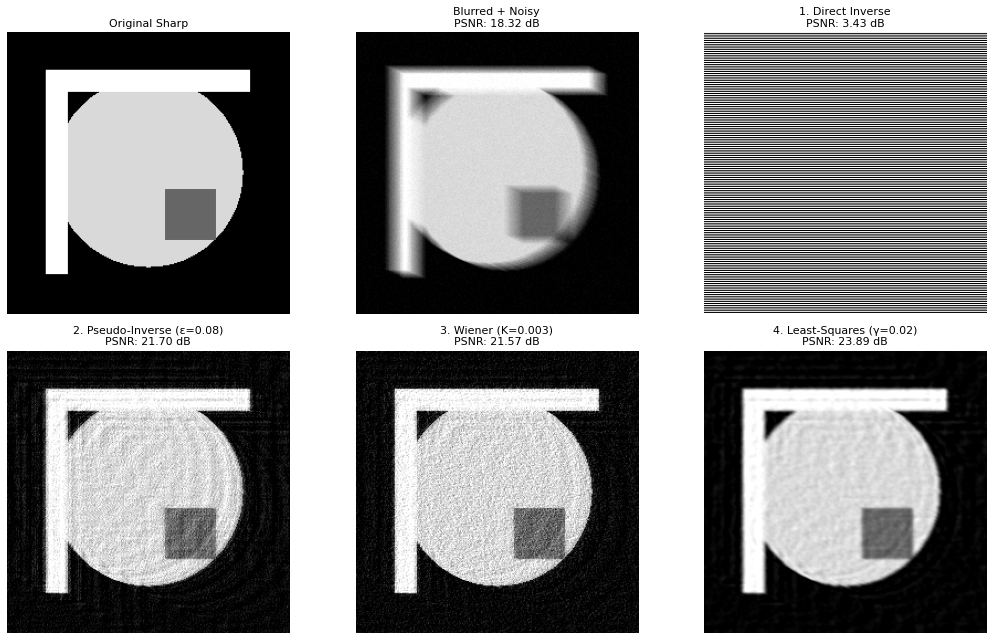

In [3]:
def compute_psnr(original: np.ndarray, restored: np.ndarray) -> float:
    mse = np.mean((original - restored) ** 2)
    return 10.0 * np.log10(1.0 / (mse + 1e-12))

results = [
    ("Original Sharp", sharp_img, None),
    ("Blurred + Noisy", degraded_img, compute_psnr(sharp_img, degraded_img)),
    ("1. Direct Inverse", res_inverse, compute_psnr(sharp_img, res_inverse)),
    ("2. Pseudo-Inverse (ε=0.08)", res_pseudo, compute_psnr(sharp_img, res_pseudo)),
    ("3. Wiener (K=0.003)", res_wiener, compute_psnr(sharp_img, res_wiener)),
    ("4. Least-Squares (γ=0.02)", res_cls, compute_psnr(sharp_img, res_cls)),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, im, psnr_val) in zip(axes.flat, results):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    label = f"{title}\nPSNR: {psnr_val:.2f} dB" if psnr_val is not None else title
    ax.set_title(label, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()